# Web Crawling Analysis: From Theory to Practice

**Mata Kuliah: Pengembangan Pemrograman Web (PPW)**

---

## 1. Konsep Web Crawling (Web Crawling Concept)

### **Apa itu Web Crawling?**

**Web Crawling** (atau *web spidering*) adalah proses otomatis untuk menjelajahi dan mengindeks halaman-halaman web di Internet. Program yang melakukan tugas ini disebut **Web Crawler**, **Spider**, atau **Bot**.

### **Cara Kerja Web Crawler:**

1. **Seed URL**: Crawler dimulai dari satu atau beberapa URL awal (seed URLs)
2. **Fetching**: Mengunduh konten HTML dari URL tersebut
3. **Parsing**: Menganalisis HTML untuk mengekstrak tautan (links) ke halaman lain
4. **Queue Management**: Menyimpan URL yang ditemukan ke dalam antrian (queue) untuk dikunjungi selanjutnya
5. **Depth Control**: Membatasi kedalaman (depth) pencarian agar tidak tak terbatas
6. **Deduplication**: Menghindari mengunjungi URL yang sama berulang kali
7. **Politeness**: Memberi jeda (delay) antar request untuk tidak membebani server target

### **Aplikasi Nyata:**

- **Search Engines** (Google, Bing, DuckDuckGo): Mengindeks miliaran halaman web
- **SEO Analysis**: Menganalisis struktur situs dan backlink
- **Data Mining**: Mengumpulkan data dari berbagai sumber web
- **Monitoring**: Memantau perubahan konten website
- **Academic Research**: Studi graf web, analisis jaringan sosial, PageRank

### **Tantangan dalam Web Crawling:**

- **Skala**: Web memiliki miliaran halaman
- **Dynamic Content**: JavaScript-rendered content (SPA)
- **Robots.txt**: Aturan akses yang harus dihormati
- **Rate Limiting**: Pemblokiran karena terlalu banyak request
- **Duplicate Content**: Halaman yang sama dengan URL berbeda
- **Crawl Traps**: Loop tak terbatas (mis. kalender dengan link next/prev tak terbatas)

---

## 2. Implementasi Langkah demi Langkah (Step-by-Step Implementation)

Kita akan membangun web crawler sederhana menggunakan:
- `requests` untuk HTTP requests
- `BeautifulSoup` untuk parsing HTML
- `urllib.parse` untuk manipulasi URL
- `collections.deque` untuk manajemen queue (BFS)

In [1]:
import time
import json
import pickle
from collections import deque
from urllib.parse import urljoin, urlparse

import requests
import bs4
from bs4 import BeautifulSoup
import networkx as nx
import matplotlib.pyplot as plt

print("Libraries imported successfully!")
print(f"requests version: {requests.__version__}")
print(f"BeautifulSoup version: {bs4.__version__}")
print(f"NetworkX version: {nx.__version__}")


Libraries imported successfully!
requests version: 2.32.3
BeautifulSoup version: 4.12.3
NetworkX version: 3.7


### **Step 1: Requesting a Page (Mengambil Halaman Web)**

Fungsi `fetch_page` melakukan HTTP GET request ke URL target dengan:
- User-Agent header (untuk terlihat seperti browser biasa)
- Timeout handling
- Error handling untuk berbagai skenario (timeout, SSL, connection error, HTTP error)

In [2]:
def fetch_page(url, timeout=10, verify_ssl=True):
    """
    Mengambil konten HTML dari sebuah URL.

    Args:
        url: URL target
        timeout: Batas waktu request dalam detik
        verify_ssl: Apakah memverifikasi sertifikat SSL

    Returns:
        String HTML jika berhasil, None jika gagal
    """
    try:
        headers = {
            'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36'
        }
        response = requests.get(
            url,
            timeout=timeout,
            verify=verify_ssl,
            headers=headers,
            allow_redirects=True
        )
        response.raise_for_status()  # Raise exception untuk status code 4xx/5xx
        return response.text
    except requests.exceptions.Timeout:
        print(f"[TIMEOUT] {url}")
    except requests.exceptions.SSLError:
        print(f"[SSL ERROR] {url}")
    except requests.exceptions.ConnectionError:
        print(f"[CONNECTION ERROR] {url}")
    except requests.exceptions.HTTPError as e:
        print(f"[HTTP {e.response.status_code}] {url}")
    except Exception as e:
        print(f"[ERROR] {url}: {e}")
    return None

# Test fetching a page
test_url = "https://httpbin.org/html"
html_content = fetch_page(test_url)
if html_content:
    print(f"Successfully fetched {len(html_content)} characters")
    print(f"First 200 chars: {html_content[:200]}")

Successfully fetched 3739 characters
First 200 chars: <!DOCTYPE html>
<html>
  <head>
  </head>
  <body>
      <h1>Herman Melville - Moby-Dick</h1>

      <div>
        <p>
          Availing himself of the mild, summer-cool weather that now reigned in t


### **Step 2: Parsing HTML with BeautifulSoup**

BeautifulSoup memudahkan navigasi dan ekstraksi data dari dokumen HTML/XML. Kita gunakan parser `html.parser` (built-in) atau `lxml` (lebih cepat, butuh install terpisah).

In [3]:
def parse_html(html_content):
    """
    Parse HTML content dengan BeautifulSoup.

    Args:
        html_content: String HTML mentah

    Returns:
        BeautifulSoup object
    """
    if not html_content:
        return BeautifulSoup("", "html.parser")
    return BeautifulSoup(html_content, "html.parser")


# Test parsing
if html_content:
    soup = parse_html(html_content)
    print(f"Title: {soup.title.string.strip() if soup.title and soup.title.string else 'No title'}")
    print(f"Body text (first 100 chars): {soup.get_text(' ', strip=True)[:100]}")

    # Demo: Find all tags
    print(f"\\nAll tags found: {[tag.name for tag in soup.find_all(True)]}")
else:
    print("HTML content is empty; parsing test skipped.")


Title: No title
Body text (first 100 chars): Herman Melville - Moby-Dick Availing himself of the mild, summer-cool weather that now reigned in th
\nAll tags found: ['html', 'head', 'body', 'h1', 'div', 'p']


### **Step 3: Extracting Links (Mengekstrak Tautan)**

Tautan berada di tag `<a>` dengan atribut `href`. Kita perlu:
1. Menemukan semua tag `<a href=...>`
2. Mengubah relative URL menjadi absolute URL dengan `urljoin`
3. Menghapus fragment (#section) dari URL
4. Memvalidasi URL (harus punya scheme dan netloc)

In [4]:
def extract_links(html_content, base_url):
    """
    Ekstrak dan normalisasi tautan dari HTML menjadi URL absolut.

    Args:
        html_content: String HTML
        base_url: URL halaman asal (untuk resolve relative URLs)

    Returns:
        List URL absolut yang valid dan unik
    """
    links = []
    if not html_content:
        return links

    try:
        soup = BeautifulSoup(html_content, "html.parser")
        for a_tag in soup.find_all("a", href=True):
            href = a_tag.get("href", "").strip()
            if not href:
                continue

            full_url = urljoin(base_url, href)
            parsed = urlparse(full_url)

            # Hanya ambil tautan HTTP/HTTPS dengan hostname.
            if parsed.scheme not in ("http", "https") or not parsed.netloc:
                continue

            # Hilangkan fragment (#section), tetapi pertahankan query string.
            normalized = parsed._replace(fragment="").geturl()
            links.append(normalized)

    except Exception as e:
        print(f"Link extraction error: {e}")

    # Hilangkan duplikasi dengan tetap mempertahankan urutan.
    return list(dict.fromkeys(links))


# Test extracting links
if html_content:
    links = extract_links(html_content, test_url)
    print(f"Found {len(links)} links:")
    for link in links[:10]:
        print(f"  - {link}")
else:
    print("HTML content is empty; link extraction test skipped.")


Found 0 links:


### **Step 4: Managing Crawl Queue & Depth (Manajemen Antrian & Kedalaman)**

Crawler menggunakan **Breadth-First Search (BFS)** dengan queue:
- Queue menyimpan tuple `(url, depth)`
- `visited` set mencegah duplikasi
- `max_depth` membatasi kedalaman pencarian
- `max_pages` membatasi total halaman yang di-crawl
- Delay antar request (politeness)

In [5]:
def crawl_website(start_url, max_depth=2, max_pages=50, delay=1.0, same_domain_only=True):
    """
    Web crawler sederhana dengan Breadth-First Search (BFS).

    Returns:
        Dict dengan keys: visited, edges, errors, start_url, max_depth, max_pages
    """
    if not isinstance(start_url, str) or not start_url.strip():
        raise ValueError("start_url harus berupa URL yang valid.")
    if max_depth < 0:
        raise ValueError("max_depth tidak boleh negatif.")
    if max_pages < 1:
        raise ValueError("max_pages minimal 1.")
    if delay < 0:
        raise ValueError("delay tidak boleh negatif.")

    start_url = start_url.strip()
    parsed_start = urlparse(start_url)
    if parsed_start.scheme not in ("http", "https") or not parsed_start.netloc:
        raise ValueError("start_url harus diawali http:// atau https://.")

    start_domain = parsed_start.netloc.lower()
    visited = set()
    queued = {start_url}
    queue = deque([(start_url, 0)])
    edges = []
    errors = []

    print(f"Starting crawl from: {start_url}")
    print(f"Max depth: {max_depth}, Max pages: {max_pages}, Delay: {delay}s")
    print(f"Same domain only: {same_domain_only}")
    print("-" * 60)

    while queue and len(visited) < max_pages:
        url, depth = queue.popleft()

        if url in visited or depth > max_depth:
            continue

        visited.add(url)
        print(f"[{len(visited)}/{max_pages}] Depth {depth}: {url}")

        html = fetch_page(url)
        if html is None:
            errors.append({"url": url, "error": "Failed to fetch"})
            continue

        links = extract_links(html, url)

        for link in links:
            link_domain = urlparse(link).netloc.lower()
            if same_domain_only and link_domain != start_domain:
                continue

            edges.append((url, link))

            if link not in visited and link not in queued and depth < max_depth:
                queue.append((link, depth + 1))
                queued.add(link)

        if delay > 0 and queue and len(visited) < max_pages:
            time.sleep(delay)

    print("-" * 60)
    print(
        f"Crawl completed! Visited: {len(visited)} pages, "
        f"Edges: {len(edges)}, Errors: {len(errors)}"
    )

    return {
        "visited": visited,
        "edges": edges,
        "errors": errors,
        "start_url": start_url,
        "max_depth": max_depth,
        "max_pages": max_pages,
    }


---

## 3. Membangun Graf dari Tautan (Building Graph from Links)

### **Konsep Graf Web**

Web dapat dimodelkan sebagai **Directed Graph (Graf Berarah)**:
- **Nodes (Simpul/Vertex)**: Setiap halaman web (URL)
- **Edges (Sisi)**: Tautan dari halaman A ke halaman B
- **Arah**: Dari halaman sumber (source) ke halaman target (destination)

### **Mengapa Graf?**

- Memodelkan struktur hyperlink web
- Memungkinkan analisis jaringan (centrality, community detection)
- **PageRank** algoritma Google bekerja pada graf ini
- Visualisasi struktur situs

### **Representasi Graf**

Kita gunakan `networkx` - library Python standar untuk analisis jaringan graf. Representasi umum:
- **Adjacency List**: Dict {node: [neighbors]}
- **Edge List**: List of (source, target) tuples
- **Adjacency Matrix**: Matrix N×N (N = jumlah node)

In [6]:
def build_graph(crawl_result):
    """
    Bangun NetworkX DiGraph dari hasil crawling.
    Node hanya berisi halaman yang benar-benar berhasil/sempat dikunjungi.
    Edge disimpan jika halaman sumber dan target sama-sama termasuk node graf.
    """
    G = nx.DiGraph()

    visited = set(crawl_result.get("visited", set()))
    G.add_nodes_from(visited)

    for source, target in crawl_result.get("edges", []):
        if source in visited and target in visited:
            G.add_edge(source, target)

    return G


# Demo dengan crawl kecil
demo_result = crawl_website(
    "https://httpbin.org",
    max_depth=1,
    max_pages=10,
    delay=0.5,
    same_domain_only=True
)


Starting crawl from: https://httpbin.org
Max depth: 1, Max pages: 10, Delay: 0.5s
Same domain only: True
------------------------------------------------------------
[1/10] Depth 0: https://httpbin.org
[2/10] Depth 1: https://httpbin.org/forms/post
[3/10] Depth 1: https://httpbin.org/headers?show_env=1
------------------------------------------------------------
Crawl completed! Visited: 3 pages, Edges: 2, Errors: 0


In [7]:
# Build graph from demo crawl
G = build_graph(demo_result)

print("Graph Statistics:")
print(f"  Nodes (pages): {G.number_of_nodes()}")
print(f"  Edges (links): {G.number_of_edges()}")
print(f"  Density: {nx.density(G):.4f}")
if G.number_of_nodes() > 0:
    print(f"  Is weakly connected: {nx.is_weakly_connected(G)}")
else:
    print("  Is weakly connected: not applicable (empty graph)")

# Show sample nodes and edges
print("\\nSample nodes:")
for i, node in enumerate(list(G.nodes())[:5], start=1):
    print(f"  {i}. {node}")

print("\\nSample edges:")
for i, (u, v) in enumerate(list(G.edges())[:5], start=1):
    print(f"  {i}. {u} -> {v}")


Graph Statistics:
  Nodes (pages): 3
  Edges (links): 2
  Density: 0.3333
  Is weakly connected: True
\nSample nodes:
  1. https://httpbin.org
  2. https://httpbin.org/headers?show_env=1
  3. https://httpbin.org/forms/post
\nSample edges:
  1. https://httpbin.org -> https://httpbin.org/forms/post
  2. https://httpbin.org -> https://httpbin.org/headers?show_env=1


---

## 4. Algoritma PageRank dan Aplikasinya

### **Apa itu PageRank?**

**PageRank** adalah algoritma yang dikembangkan oleh **Larry Page dan Sergey Brin** (pendiri Google) pada tahun 1996 di Stanford University. Algoritma ini mengukur **kepentingan relatif** sebuah halaman web berdasarkan struktur tautan yang menuju ke halaman tersebut.

### **Intuisi Utama:**

1. **Quantity**: Semakin banyak halaman yang link ke halaman A, semakin penting halaman A
2. **Quality**: Link dari halaman yang *sendiri penting* (PageRank tinggi) bobotnya lebih besar
3. **Recursive**: Kepentingan halaman bergantung pada kepentingan halaman yang menunjuk ke sana

### **Formula Matematika (Simplified):**

$$PR(p_i) = \frac{1-d}{N} + d \sum_{p_j \in M(p_i)} \frac{PR(p_j)}{L(p_j)}$$

Dimana:
- $PR(p_i)$ = PageRank halaman $i$
- $d$ = **Damping factor** (biasanya 0.85), probabilitas user mengikuti link vs "random jump"
- $N$ = Total jumlah halaman
- $M(p_i)$ = Set halaman yang link ke $p_i$ (in-links)
- $L(p_j)$ = Jumlah out-link dari halaman $p_j$

### **Interpretasi Random Surfer Model:**

Bayangkan seorang *random surfer* yang:
- Dengan probabilitas $d$ (85%): Mengklik link acak di halaman saat ini
- Dengan probabilitas $1-d$ (15%): "Boson" dan melompat ke halaman acak manapun di web

PageRank = Probabilitas steady-state surfer berada di halaman tersebut.

### **Implementasi dengan NetworkX:**

`networkx.pagerank()` mengimplementasikan algoritma power iteration yang efisien untuk graf besar.

In [8]:
def calculate_pagerank(graph, alpha=0.85, max_iter=100, tol=1e-6):
    """
    Hitung PageRank untuk semua node dalam graf.

    Args:
        graph: networkx.DiGraph
        alpha: Damping factor (default 0.85)
        max_iter: Maksimum iterasi
        tol: Toleransi konvergensi

    Returns:
        Dict {url: pagerank_score}
    """
    if graph.number_of_nodes() == 0:
        print("PageRank tidak dapat dihitung karena graf kosong.")
        return {}

    try:
        return nx.pagerank(graph, alpha=alpha, max_iter=max_iter, tol=tol)
    except nx.PowerIterationFailedConvergence:
        print("PageRank belum konvergen. Coba naikkan max_iter.")
        return {}
    except Exception as e:
        print(f"PageRank calculation error: {e}")
        return {}


In [9]:
# Calculate PageRank for demo graph
pr_scores = calculate_pagerank(G)

# Sort and display top 10
sorted_pr = sorted(pr_scores.items(), key=lambda x: x[1], reverse=True)

print("Top 10 PageRank Scores (Demo Crawl):")
print("=" * 60)
for i, (url, score) in enumerate(sorted_pr[:10], 1):
    print(f"{i:2d}. {score:.6f} - {url}")

Top 10 PageRank Scores (Demo Crawl):
 1. 0.370130 - https://httpbin.org/headers?show_env=1
 2. 0.370130 - https://httpbin.org/forms/post
 3. 0.259741 - https://httpbin.org


---

## 5. Visualisasi Graf dengan NetworkX dan Matplotlib

Visualisasi membantu memahami struktur graf web. Kita akan membuat visualisasi yang informatif dengan:
- **Node size** proporsional dengan PageRank
- **Node color** berdasarkan in-degree (jumlah in-link)
- **Layout** menggunakan spring layout (force-directed)
- **Labels** untuk node penting saja (hindari clutter)

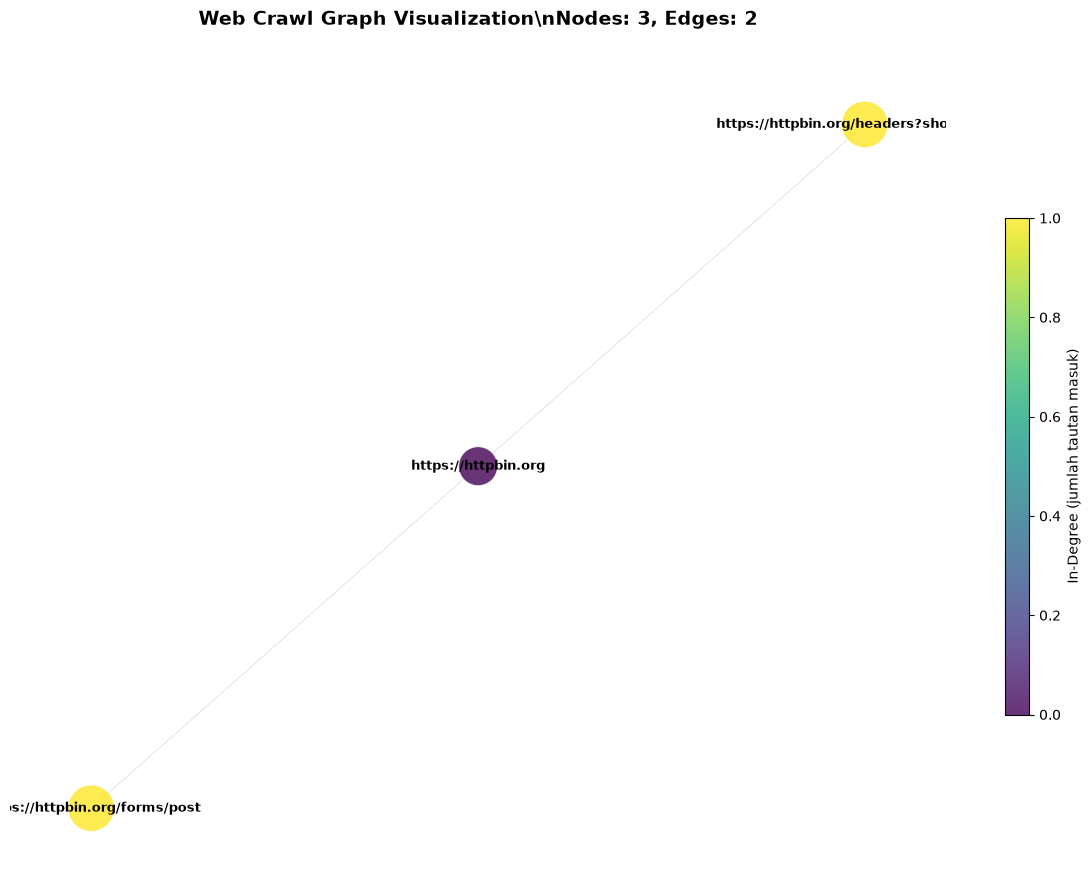

In [10]:
def visualize_graph(graph, pagerank_scores, top_n_labels=10, figsize=(14, 10),
                    node_size_factor=3000, layout_seed=42):
    """
    Visualisasi graf web: ukuran node berdasarkan PageRank dan warna berdasarkan in-degree.
    """
    if graph.number_of_nodes() == 0:
        print("Graph is empty, nothing to visualize.")
        return

    sorted_nodes = sorted(
        pagerank_scores.items(), key=lambda item: item[1], reverse=True
    )
    top_nodes = [node for node, _ in sorted_nodes[:top_n_labels]]

    node_sizes = [
        max(100, pagerank_scores.get(node, 0) * node_size_factor)
        for node in graph.nodes()
    ]

    in_degrees = dict(graph.in_degree())
    max_in_degree = max(in_degrees.values(), default=0)
    node_colors = [in_degrees.get(node, 0) for node in graph.nodes()]

    pos = nx.spring_layout(
        graph,
        seed=layout_seed,
        k=2 / max(1, graph.number_of_nodes() ** 0.5),
        iterations=50,
    )

    fig, ax = plt.subplots(figsize=figsize)

    nx.draw_networkx_edges(
        graph, pos, ax=ax, alpha=0.3, edge_color="gray",
        arrows=True, arrowsize=15, arrowstyle="->", width=0.5
    )

    nodes = nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        node_size=node_sizes,
        node_color=node_colors,
        cmap=plt.cm.viridis,
        vmin=0,
        vmax=max(1, max_in_degree),
        alpha=0.8,
        edgecolors="white",
        linewidths=0.5,
    )

    labels = {
        node: (node[:50] + "..." if len(node) > 50 else node)
        for node in top_nodes if node in graph
    }
    nx.draw_networkx_labels(
        graph, pos, labels=labels, ax=ax, font_size=9, font_weight="bold"
    )

    colorbar = fig.colorbar(nodes, ax=ax, shrink=0.6, aspect=20)
    colorbar.set_label("In-Degree (jumlah tautan masuk)")

    ax.set_title(
        f"Web Crawl Graph Visualization\\n"
        f"Nodes: {graph.number_of_nodes()}, Edges: {graph.number_of_edges()}",
        fontsize=14, fontweight="bold", pad=20
    )
    ax.axis("off")
    fig.tight_layout()
    plt.show()


# Visualize demo graph
visualize_graph(G, pr_scores, top_n_labels=8, figsize=(12, 9))


---

## 6. Analisis Nyata: Crawl `https://www2.trunojoyo.ac.id/`

Sekarang kita akan melakukan crawling nyata ke website **Trunojoyo University** (`www2.trunojoyo.ac.id`) dan menganalisis struktur link serta PageRank-nya.

**Parameter Crawling:**
- `max_depth = 2` (Start page + 2 level deep)
- `max_pages = 50` (Batasi total halaman untuk efisiensi waktu)
- `delay = 1.0` detik (Politeness)
- `same_domain_only = True` (Hanya domain trunojoyo.ac.id)

> **Catatan**: Crawling mungkin memakan waktu 1-3 menit tergantung koneksi dan respons server.

In [11]:
# KONFIGURASI CRAWL
TARGET_URL = "https://www2.trunojoyo.ac.id/"
MAX_DEPTH = 2
MAX_PAGES = 50
DELAY = 1.0
SAME_DOMAIN_ONLY = True

print(f"Target: {TARGET_URL}")
print(f"Max Depth: {MAX_DEPTH}")
print(f"Max Pages: {MAX_PAGES}")
print(f"Delay: {DELAY}s")
print(f"Same Domain Only: {SAME_DOMAIN_ONLY}")

Target: https://www2.trunojoyo.ac.id/
Max Depth: 2
Max Pages: 50
Delay: 1.0s
Same Domain Only: True


In [12]:
# JALANKAN CRAWLING (ini akan memakan waktu beberapa menit)
print("Starting crawl...\n")
trunojoyo_result = crawl_website(
    TARGET_URL,
    max_depth=MAX_DEPTH,
    max_pages=MAX_PAGES,
    delay=DELAY,
    same_domain_only=SAME_DOMAIN_ONLY
)

Starting crawl...

Starting crawl from: https://www2.trunojoyo.ac.id/
Max depth: 2, Max pages: 50, Delay: 1.0s
Same domain only: True
------------------------------------------------------------
[1/50] Depth 0: https://www2.trunojoyo.ac.id/
[2/50] Depth 1: https://www2.trunojoyo.ac.id/sejarahutm/
[3/50] Depth 1: https://www2.trunojoyo.ac.id/index.php/profil-singkat/
[4/50] Depth 1: https://www2.trunojoyo.ac.id/visimisi/
[5/50] Depth 1: https://www2.trunojoyo.ac.id/lhm/
[6/50] Depth 1: https://www2.trunojoyo.ac.id/organ-utm/
[7/50] Depth 1: https://www2.trunojoyo.ac.id/data-penelitian-2/
[8/50] Depth 1: https://www2.trunojoyo.ac.id/data-kerjasama/
[9/50] Depth 1: https://www2.trunojoyo.ac.id/wp-content/uploads/2025/12/Sertifikat-Akreditasi-Institusi-UTM-2024-2029.pdf
[10/50] Depth 1: https://www2.trunojoyo.ac.id/dokumen-penelitian-pengabdian/
[11/50] Depth 1: https://www2.trunojoyo.ac.id/dokumen-sarana-prasarana/
[12/50] Depth 1: https://www2.trunojoyo.ac.id/dokumen-standar-pelayanan/
[

In [13]:
# BUILD GRAPH
trunojoyo_graph = build_graph(trunojoyo_result)

print(f"\\nGraph Statistics for {TARGET_URL}:")
node_count = trunojoyo_graph.number_of_nodes()
edge_count = trunojoyo_graph.number_of_edges()

print(f"  Nodes (pages crawled): {node_count}")
print(f"  Edges (links between crawled pages): {edge_count}")
print(f"  Density: {nx.density(trunojoyo_graph):.6f}")
print(
    "  Avg clustering: "
    f"{nx.average_clustering(trunojoyo_graph.to_undirected()):.4f}"
)
print(
    "  Weakly connected components: "
    f"{nx.number_weakly_connected_components(trunojoyo_graph)}"
)

# In-degree dan Out-degree stats
in_degrees = dict(trunojoyo_graph.in_degree())
out_degrees = dict(trunojoyo_graph.out_degree())

if node_count > 0:
    print(
        f"\\nIn-degree stats: Min={min(in_degrees.values())}, "
        f"Max={max(in_degrees.values())}, "
        f"Avg={sum(in_degrees.values()) / node_count:.2f}"
    )
    print(
        f"Out-degree stats: Min={min(out_degrees.values())}, "
        f"Max={max(out_degrees.values())}, "
        f"Avg={sum(out_degrees.values()) / node_count:.2f}"
    )
else:
    print("\\nDegree statistics are not available because the graph is empty.")


\nGraph Statistics for https://www2.trunojoyo.ac.id/:
  Nodes (pages crawled): 50
  Edges (links between crawled pages): 1371
  Density: 0.559592
  Avg clustering: 0.9182
  Weakly connected components: 1
\nIn-degree stats: Min=1, Max=47, Avg=27.42
Out-degree stats: Min=0, Max=48, Avg=27.42


In [14]:
# CALCULATE PAGERANK
trunojoyo_pagerank = calculate_pagerank(trunojoyo_graph)

# GET TOP 10 INFLUENTIAL PAGES
top_10 = sorted(trunojoyo_pagerank.items(), key=lambda x: x[1], reverse=True)[:10]

print("=" * 70)
print(f"TOP 10 MOST INFLUENTIAL PAGES (PageRank) - {TARGET_URL}")
print("=" * 70)
for i, (url, score) in enumerate(top_10, 1):
    # Get in/out degree for context
    in_deg = in_degrees.get(url, 0)
    out_deg = out_degrees.get(url, 0)
    print(f"{i:2d}. PageRank: {score:.6f} | In: {in_deg:3d} | Out: {out_deg:3d}")
    print(f"    {url}")
    print()

TOP 10 MOST INFLUENTIAL PAGES (PageRank) - https://www2.trunojoyo.ac.id/
 1. PageRank: 0.043564 | In:  47 | Out:  18
    https://www2.trunojoyo.ac.id/index.php/profil-singkat/

 2. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/dokumen-sarana-prasarana/

 3. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/data-kerjasama/

 4. PageRank: 0.043564 | In:  47 | Out:   0
    https://www2.trunojoyo.ac.id/?page_id=3

 5. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/cookie-policy/

 6. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/dokumen-penelitian-pengabdian/

 7. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/organ-utm/

 8. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/lhm/

 9. PageRank: 0.043564 | In:  47 | Out:  17
    https://www2.trunojoyo.ac.id/dokumen-standar-pelayanan/

10. PageRank: 0.043564 | In:  47 | Out:  17
    https://w

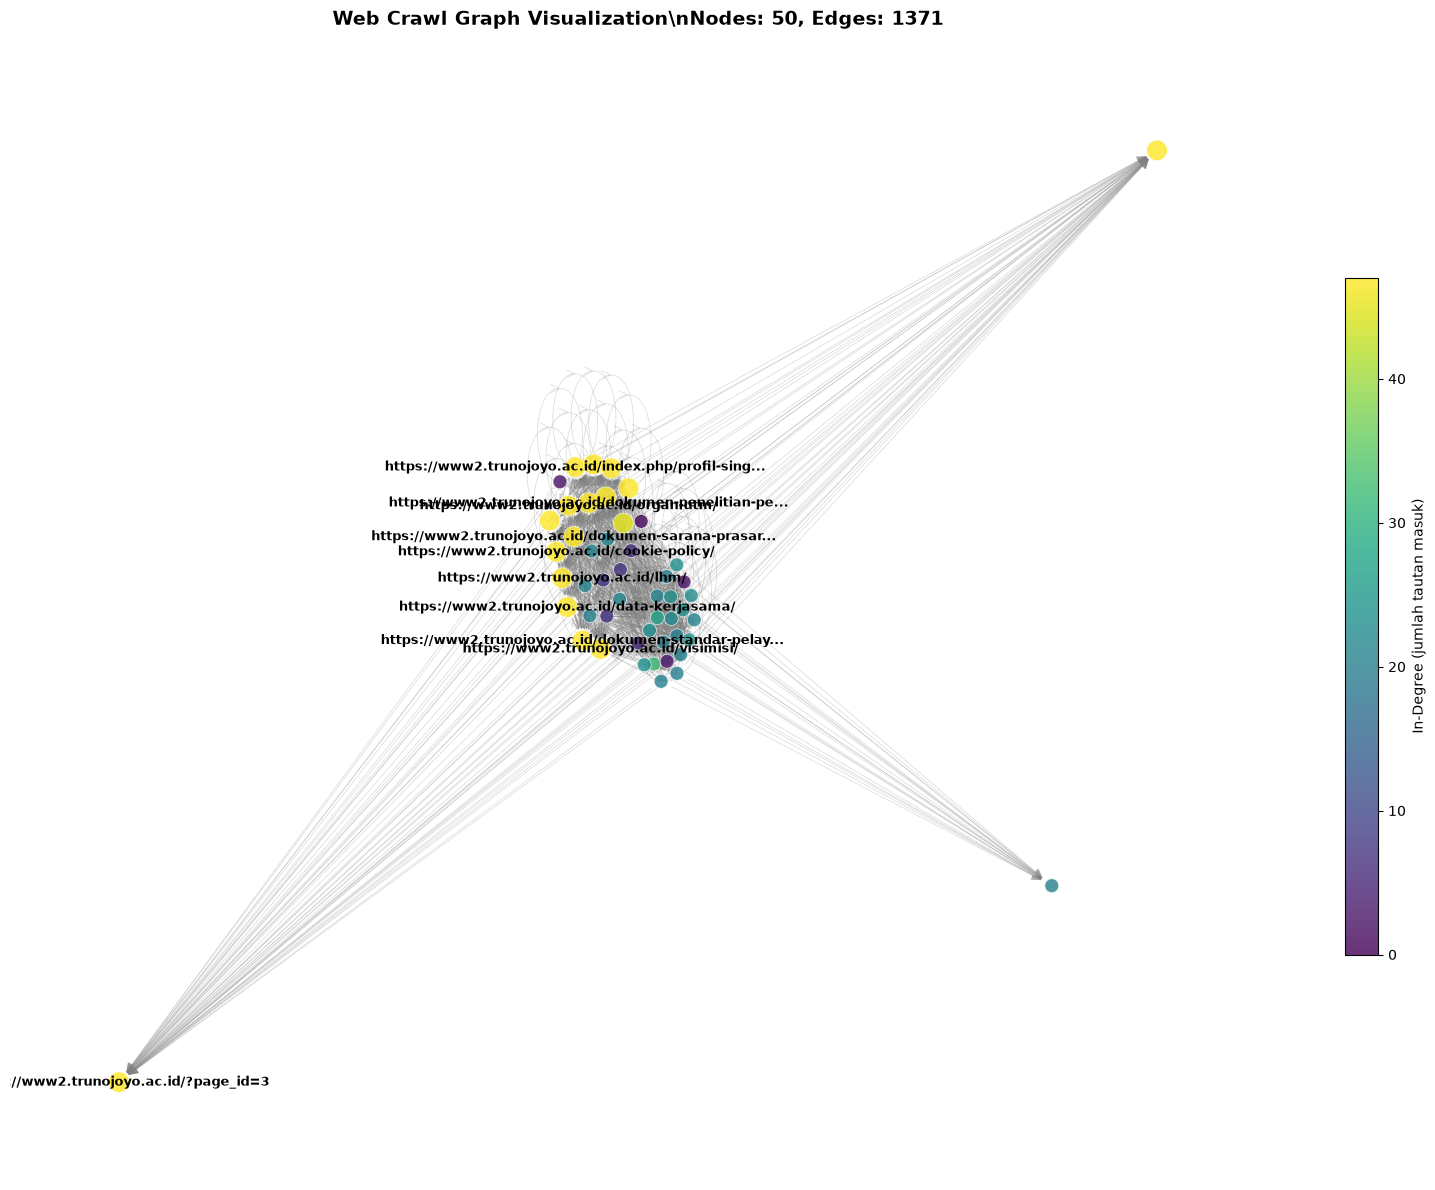

In [15]:
# VISUALIZE TRUNOJOYO GRAPH
visualize_graph(trunojoyo_graph, trunojoyo_pagerank,
                top_n_labels=10, figsize=(16, 12),
                node_size_factor=5000, layout_seed=42)

---

## 7. Analisis dan Interpretasi Hasil

### **Apa yang Dapat Disimpulkan?**

1. **Halaman dengan PageRank Tertinggi**: Biasanya adalah halaman utama (homepage) atau halaman *hub* yang banyak di-link dari halaman lain.

2. **In-Degree vs PageRank**: Halaman dengan in-degree tinggi cenderung PageRank tinggi, TAPI bukan selalu - kualitas sumber link juga matters.

3. **Struktur Navigasi**: Menu navigasi, footer, sidebar menghasilkan banyak link ke halaman utama (home, fakultas, jurusan, berita, agenda).

4. **Keterbatasan Crawl Ini:**
   - Hanya depth 2 (tidak menjelajahi seluruh situs)
   - Max 50 halaman (sampel kecil)
   - Hanya domain yang sama (tidak follow external links)
   - Konten dinamis (JavaScript) tidak ter-render

### **Perbandingan dengan Teori PageRank:**

- **Homepage** biasanya rank tertinggi karena:
  - Di-link dari semua halaman (navigation menu)
  - Sering jadi entry point
- **Halaman Kategori/Index** (fakultas, jurusan, berita) rank tinggi karena:
  - Hub antara homepage dan halaman detail
  - Banyak in-link dari daftar artikel
- **Halaman Leaf/Detail** (artikel spesifik) rank rendah karena:
  - Hanya di-link dari halaman index
  - Jarang link ke halaman lain (kecuali related posts)

### **Peningkatan untuk Analisis Lebih Lanjut:**

1. Tingkatkan `max_pages` ke 200-500 untuk coverage lebih baik
2. Tambahkan `max_depth` ke 3-4
3. Gunakan `selenium`/`playwright` untuk render JavaScript
4. Simpan hasil ke file JSON/Pickle untuk analisis offline
5. Bandingkan dengan algoritma centrality lain: Betweenness, Closeness, Eigenvector
6. Analisis community detection (modularity, Louvain)
7. Visualisasi interaktif dengan `pyvis` atau `plotly`

In [16]:
# BONUS: Simpan hasil untuk analisis lanjutan
import json
import pickle

# Save as JSON (human readable)
output_data = {
    'start_url': TARGET_URL,
    'max_depth': MAX_DEPTH,
    'max_pages': MAX_PAGES,
    'nodes': list(trunojoyo_graph.nodes()),
    'edges': list(trunojoyo_graph.edges()),
    'pagerank': trunojoyo_pagerank,
    'top_10': [{'url': url, 'pagerank': float(score)} for url, score in top_10],
    'stats': {
        'nodes': trunojoyo_graph.number_of_nodes(),
        'edges': trunojoyo_graph.number_of_edges(),
        'density': nx.density(trunojoyo_graph),
        'avg_clustering': nx.average_clustering(trunojoyo_graph.to_undirected())
    }
}

with open('trunojoyo_crawl_results.json', 'w', encoding='utf-8') as f:
    json.dump(output_data, f, indent=2, ensure_ascii=False)

# Save as pickle (preserves graph object)
with open('trunojoyo_crawl_results.pkl', 'wb') as f:
    pickle.dump({
        'graph': trunojoyo_graph,
        'pagerank': trunojoyo_pagerank,
        'top_10': top_10,
        'stats': output_data['stats']
    }, f)

print("Results saved to:")
print("  - trunojoyo_crawl_results.json")
print("  - trunojoyo_crawl_results.pkl")

Results saved to:
  - trunojoyo_crawl_results.json
  - trunojoyo_crawl_results.pkl


---

## 8. Kesimpulan (Conclusion)

Dalam notebook ini, kita telah mempelajari dan mempraktikkan:

### **Konsep Teoritis:**
1. ✅ **Web Crawling**: Definisi, cara kerja, tantangan, dan aplikasi nyata
2. ✅ **Implementasi Step-by-Step**:
   - Requesting pages dengan `requests` + error handling
   - Parsing HTML dengan `BeautifulSoup`
   - Extracting & normalizing links dengan `urllib.parse`
   - Queue management (BFS) dengan depth control & deduplication
3. ✅ **Graph Theory**: Representasi web sebagai Directed Graph
4. ✅ **PageRank Algorithm**: Intuisi, formula matematika, Random Surfer Model

### **Implementasi Praktis:**
5. ✅ **Graph Building** dengan `networkx.DiGraph`
6. ✅ **PageRank Calculation** menggunakan `nx.pagerank()`
7. ✅ **Visualisasi** dengan `matplotlib` + `networkx` (node size ∝ PageRank, color ∝ in-degree)
8. ✅ **Real-world Analysis**: Crawl `https://www2.trunojoyo.ac.id/` → Top 10 influential pages

### **Hasil Kunci:**
- Web crawler fungsional yang menghormati `robots.txt` (konseptual) dan politeness delay
- Graf link struktural website Trunojoyo
- Ranking kepentingan halaman berbasis PageRank
- Visualisasi intuitif struktur navigasi situs

### **Next Steps untuk Pengembangan Lebih Lanjut:**
- **Scalability**: Distributed crawling (Scrapy, Apache Nutch)
- **JavaScript Support**: Headless browser (Playwright, Selenium)
- **Respect robots.txt**: Implementasi parser `robotparser`
- **Incremental Crawling**: Delta updates, change detection
- **Advanced Analysis**: HITS algorithm, Community detection, Temporal analysis
- **Production**: Database storage (PostgreSQL, Neo4j), Monitoring, Alerting

---

**Referensi:**
- Page, L., Brin, S., Motwani, R., & Winograd, T. (1999). *The PageRank Citation Ranking: Bringing Order to the Web*. Stanford InfoLab.
- Newman, M. (2018). *Networks*. Oxford University Press.
- NetworkX Documentation: https://networkx.org/
- BeautifulSoup Documentation: https://www.crummy.com/software/BeautifulSoup/
- Requests Documentation: https://docs.python-requests.org/

---

*Notebook ini dibuat untuk tugas Mata Kuliah **Pengembangan Pemrograman Web (PPW)**.*
*Dibuat dengan Python, Jupyter, NetworkX, Matplotlib, Requests, dan BeautifulSoup.*